# 00 — CADDY Dataset Exploratory Data Analysis

**Phase 2.0 | SENSE Project**

Surfaces class imbalance, scenario imbalance, and data-quality issues
*before* any split is frozen. All findings are written to
`data/processed/eda_findings.md`.

Full computations also available as a script: `scripts/run_eda.py`.


In [1]:
import os
PROJECT_ROOT = r'C:\Users\Tamim Syeedur Rahman\All Codes\sense-project'
os.chdir(PROJECT_ROOT)
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
from src.config import Paths

CADDY_ROOT    = Path(Paths.CADDY_ROOT)
CSV_POSITIVES = Path(Paths.CADDY_CSV_POSITIVES)
CSV_NEGATIVES = Path(Paths.CADDY_CSV_NEGATIVES)
PROCESSED_DIR = Path('data/processed')

df_pos = pd.read_csv(CSV_POSITIVES)
df_neg = pd.read_csv(CSV_NEGATIVES)
df_pos_real = df_pos[df_pos['synthetic'] == 0].copy()
df_neg_real = df_neg[df_neg['synthetic'] == 0].copy()

print('Real positive stereo pairs :', len(df_pos_real))
print('Real negative stereo pairs :', len(df_neg_real))
print('Total real stereo pairs    :', len(df_pos_real) + len(df_neg_real))


Real positive stereo pairs : 9239
Real negative stereo pairs : 7190
Total real stereo pairs    : 16429


## 1. Per-gesture-class sample distribution

label name
backwards         561
boat              369
carry             717
down              462
end_comm         1318
five               48
four              235
here              261
mosaic            226
num_delimiter     992
one               161
photo             925
start_comm       1820
three             388
two               404
up                352

MIN: 48 (five)
MAX: 1820 (start_comm)
Imbalance ratio: 37.9x


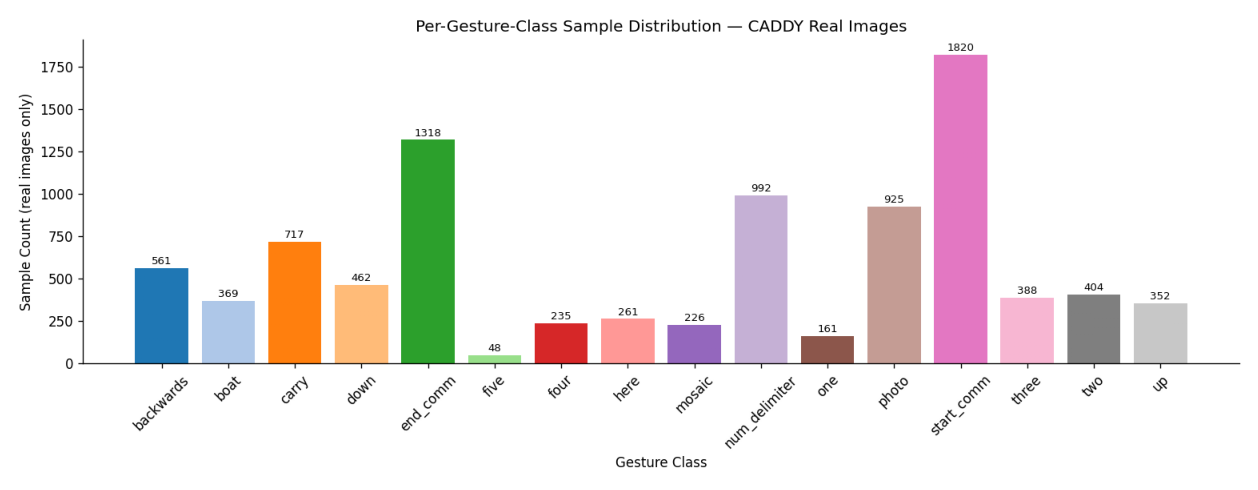

In [2]:
gesture_counts = df_pos_real['label name'].value_counts().sort_index()
print(gesture_counts.to_string())
min_cls = gesture_counts.idxmin()
max_cls = gesture_counts.idxmax()
ratio = gesture_counts.max() / gesture_counts.min()
print(f'\nMIN: {gesture_counts.min()} ({min_cls})')
print(f'MAX: {gesture_counts.max()} ({max_cls})')
print(f'Imbalance ratio: {ratio:.1f}x')

fig, ax = plt.subplots(figsize=(13, 5))
img = mpimg.imread(str(PROCESSED_DIR / 'eda_class_distribution.png'))
ax.imshow(img)
ax.axis('off')
plt.tight_layout()
plt.show()


## 2. Per-scenario sample distribution

             positives  negatives  total
scenario                                
biograd-A         1728       1313   3041
biograd-B          975        797   1772
biograd-C         1805       1487   3292
brodarski-A        227        220    447
brodarski-B         87         70    157
brodarski-C        773        212    985
brodarski-D        324        304    628
genova-A          3320       2787   6107
Scenario imbalance ratio: 38.160919540229884


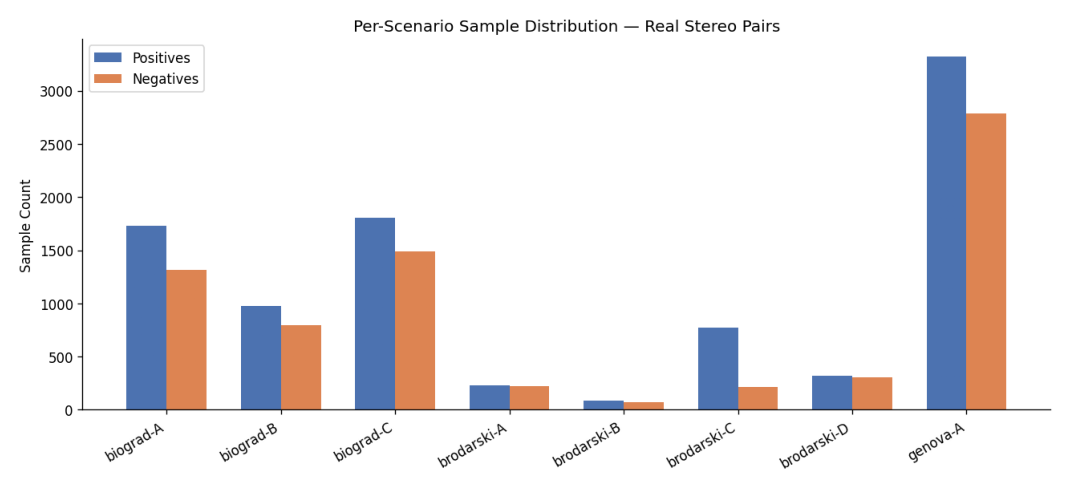

In [3]:
scenario_pos = df_pos_real['scenario'].value_counts().sort_index()
scenario_neg = df_neg_real['scenario'].value_counts().sort_index()
scenario_df = pd.concat(
    [scenario_pos.rename('positives'), scenario_neg.rename('negatives')], axis=1
).fillna(0).astype(int)
scenario_df['total'] = scenario_df['positives'] + scenario_df['negatives']
print(scenario_df.to_string())
print('Scenario imbalance ratio:', scenario_df['positives'].max() / scenario_df['positives'].min())

fig, ax = plt.subplots(figsize=(11, 5))
img = mpimg.imread(str(PROCESSED_DIR / 'eda_scenario_distribution.png'))
ax.imshow(img)
ax.axis('off')
plt.tight_layout()
plt.show()


## 3. Stereo pair visual spot-check (one per scenario)

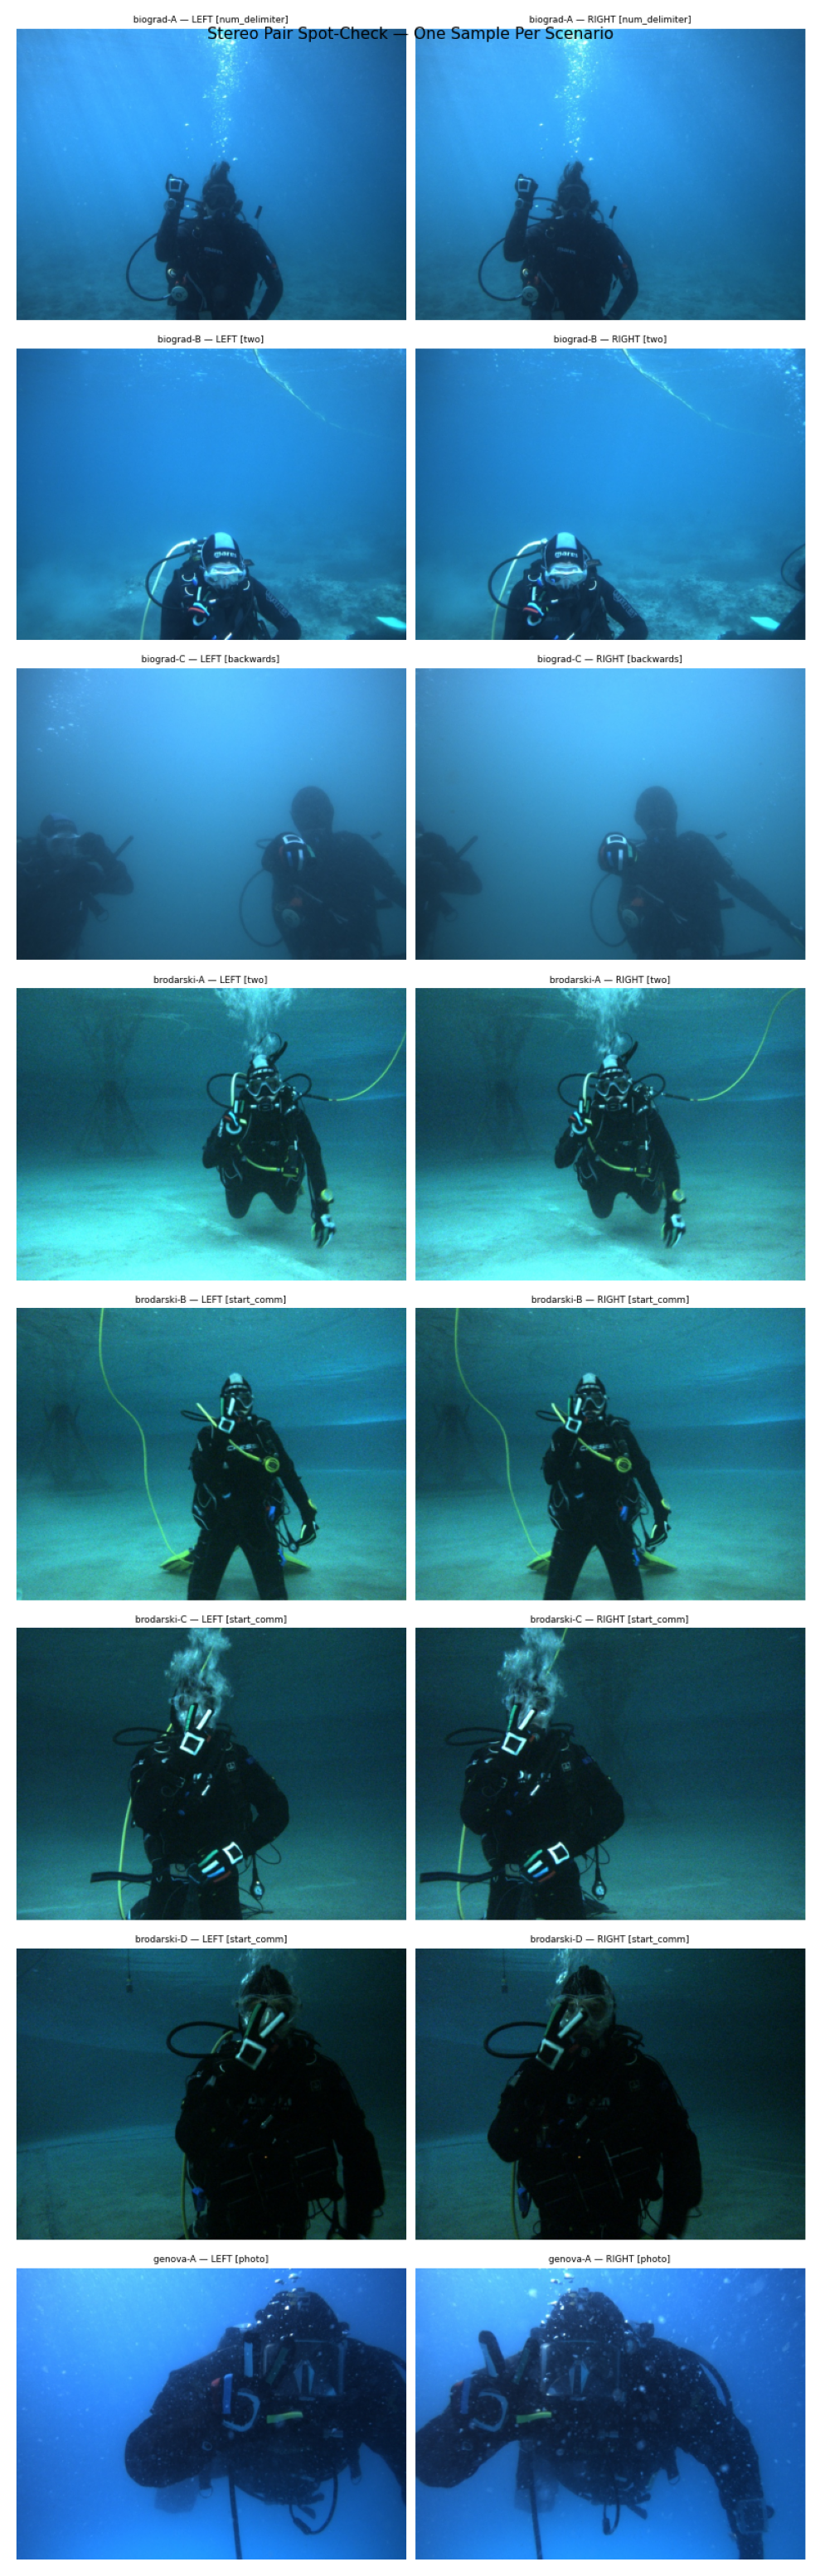

In [4]:
fig, ax = plt.subplots(figsize=(10, 32))
img = mpimg.imread(str(PROCESSED_DIR / 'eda_stereo_spot_check.png'))
ax.imshow(img)
ax.axis('off')
plt.tight_layout()
plt.show()


## 4. Gesture class distribution per scenario

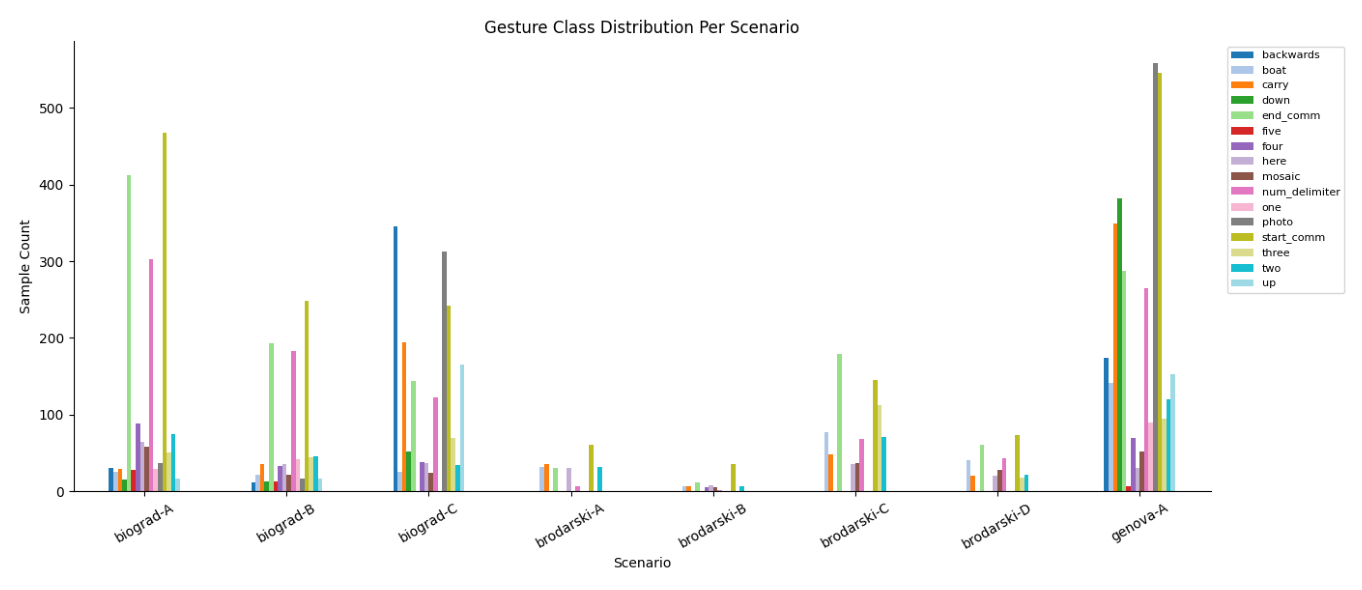

In [5]:
fig, ax = plt.subplots(figsize=(14, 6))
img = mpimg.imread(str(PROCESSED_DIR / 'eda_class_per_scenario.png'))
ax.imshow(img)
ax.axis('off')
plt.tight_layout()
plt.show()


## 5. EDA Findings Summary

In [6]:
findings_path = PROCESSED_DIR / 'eda_findings.md'
print(findings_path.read_text(encoding='utf-8'))


# EDA Findings — CADDY Dataset

Generated by: `scripts/run_eda.py` + `notebooks/00_data_exploration.ipynb` (Phase 2.0)

---

## 1. Class Imbalance (Gesture Classes)

**Finding: SEVERE class imbalance is present.**

- Minimum class: `five` with **48** samples
- Maximum class: `start_comm` with **1820** samples
- Imbalance ratio: **37.9x**

Per-class counts (sorted alphabetically):

| Gesture Class | Count |
|---|---|
| `backwards` | 561 |
| `boat` | 369 |
| `carry` | 717 |
| `down` | 462 |
| `end_comm` | 1318 |
| `five` | 48 |
| `four` | 235 |
| `here` | 261 |
| `mosaic` | 226 |
| `num_delimiter` | 992 |
| `one` | 161 |
| `photo` | 925 |
| `start_comm` | 1820 |
| `three` | 388 |
| `two` | 404 |
| `up` | 352 |

**Implication for splitting (P2.2):** Stratification on `gesture_id` is mandatory.
The max/min ratio is 37.9x. Without stratification, the smallest
class (`five`, 48 samples) risks being absent from val/test splits,
making per-class metrics unreliable.

---

## 2. Scenario Imbalan